# DSHARP data analysis and dust dynamics

## Importing packages

In [2]:
import numpy as np
from astropy.io import ascii
import astropy.units as u
from astropy import constants as const
from scipy.integrate import simps
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rc('text', usetex = True)
#mpl.rc('font', family = 'serif')
import ipywidgets as widgets
from ipywidgets import interact, interact_manual

## Looking at the AS205 system

### AS205 properties

In [3]:
filename="../DSharp data/AS205.profile.txt"
bmaj = 38*u.milliarcsecond
bmin = 25*u.milliarcsecond
L_sol = 10**0.33*const.L_sun
kappa_dust = 2 * u.cm**2 * u.g**(-1)
nu = 233.7 * u.GHz
macc = 10**(-7.4)*u.year**(-1) * u.solMass
H = 0.02
mu = 2.3
mstar = 10**(-0.06)*u.solMass

### Alma data analysis function

Here we set up a function for calculating the desired values from the DSHARP data set.

we will calculate the midplane temperature as $$ T_{mid}(r) = \left( \frac{\varphi L_*}{8\pi r^2 \sigma_{SB}}\right)^{1/4}\, $$

This we can use with blackbody radiation
$$ B_\nu(T) = \frac{2 h\nu^3}{c^2} \frac{1}{\exp\left({h\nu \over k_B T}\right) - 1}
= 0.48\,\textrm{J as}^{-2}\frac{1}{\exp\left({11.5 \textrm{K} \over T}\right) - 1} $$

This we can use to find the surface density by the fact that $ I_\nu = B_\nu(T) ( 1 - \exp(-\tau_\nu) )\,, $ which is the observation, and using $ \tau_\nu = \kappa_\nu \Sigma_d(r) $, given a $\kappa$ and $\nu$ as specified above


we also calculate sound speed
$$c_{s}=\sqrt{\frac{\gamma k_{\mathrm{B}} T}{m}}$$

The Toomre parameter: $$Q \equiv \frac{c_{s} \Omega}{\pi G \Sigma}$$

And also the alpha parameter which is given by $$\alpha = \frac{\Omega_K}{cs^2} \frac{M_{acc}}{3\pi \Sigma_g}$$

In [4]:
def alma_disk(filename):
  
    t = ascii.read(filename)
    bw = np.pi * (bmaj*bmin)/(4*np.log(2))
    bw = bw.to(u.arcsecond**2)

    r_au = t[0][:]*u.au
    Inu = t[2][:]*u.jansky / bw
    sInu = t[3][:]*u.jansky / bw
    
    @interact
    def plot(scale = ["symlog","linear"]):
        plt.figure()
        #plt.subplot(121)
        plt.plot(r_au, Inu)
        plt.yscale(scale,linthreshy=0.015)
        plt.grid(True)
        plt.ylabel(r"Inu  $ \left [ \displaystyle \frac{Jansky}{arcsecond^2} \right ] $ ",fontsize="16")
        plt.xlabel("r [AU]",fontsize="16")
        plt.show()

    return r_au, Inu

def alma_ana(xlow,xhigh,r_au,Inu,mstar,L_sol,nu,macc,mu,kappa_dust):
    bol = (r_au>xlow*u.au) & (r_au<xhigh*u.au) & (Inu > 0)

    T_mid = ( (0.02*L_sol) / (8*np.pi*(r_au)**2 * const.sigma_sb) )**(1/4)
    T_mid = T_mid.to(u.K)

    B_nu = 0.48*u.Jy*(u.arcsecond)**(-2)*(1/(np.exp(11.5*u.K/T_mid) -1 ))

    tau_nu = -np.log(1. - Inu / B_nu)
    tau_nu = tau_nu.decompose()

    tau_nu_disk = tau_nu[bol]
    tau_nu_diskv = tau_nu_disk[~np.isnan(tau_nu_disk)]

    r_au_val = r_au[bol]
    r_au_val = r_au_val[~np.isnan(tau_nu_disk)]

    T_mid_val = T_mid[bol]
    T_mid_val = T_mid_val[~np.isnan(tau_nu_disk)]

    sigma = tau_nu_diskv/kappa_dust
    sigma_gas = sigma * 100
    mass_dust = simps(sigma.to(u.g*u.cm**(-2)) * 2. * np.pi * r_au_val.to(u.cm), x=r_au_val.to(u.cm)) * u.g
    # mass_gas = simps(sigma_gas.to(u.g*u.cm**(-2)) * 2. * np.pi * r_au_val.to(u.cm), x=r_au_val.to(u.cm)) * u.g
    mass_gas = mass_dust * 100
    print("Disk range: ", xlow, xhigh)

    print("gas mass:", mass_gas.to(u.jupiterMass))
    print("gas mass:", mass_gas.to(u.solMass))
    print("Dust mass:", mass_dust.to(u.jupiterMass))
    print("Dust mass:", mass_dust.to(u.solMass))
    print("Total : ", (mass_dust+mass_gas).to(u.solMass))


    cs = np.sqrt(const.k_B*T_mid_val/(mu*const.m_p))
    cs = cs.to(u.m/u.s)
    Omega_K = np.sqrt(const.G * mstar / r_au_val**3)

    # alpha = vr/(cs*H)
    alpha = Omega_K / cs**2 * macc / (3. * np.pi * sigma_gas)
    alpha = alpha.decompose()


    print("lifetime:", ((mass_gas)/macc).to(u.yr))

    Q = cs*Omega_K/(np.pi*const.G*sigma_gas)
    Q = Q.decompose()
    
       
    @interact
    def plot(scale = ["symlog","linear"]):
        fig, ax = plt.subplots(2,2)
        
        ax[0][0].plot(r_au[bol].to(u.au),T_mid[bol].to(u.K))
        ax[0][0].set_yscale(scale,linthreshy=0.015)
        ax[0][0].grid(True)
        ax[0][0].set_ylabel(r"  $ T_{mid} [K] $ ",fontsize="16")
        ax[0][0].set_xlabel("r [AU]",fontsize="16")
        
        ax[1][0].plot(r_au[bol].to(u.au),tau_nu[bol].decompose())
        ax[1][0].set_yscale(scale,linthreshy=0.015)
        ax[1][0].grid(True)
        ax[1][0].set_ylabel(r"$\tau$ ",fontsize="16")
        ax[1][0].set_xlabel("r [AU]",fontsize="16")
        
        ax[1][1].plot(r_au_val.to(u.au),alpha)
        ax[1][1].set_yscale(scale,linthreshy=0.015)
        ax[1][1].grid(True)
        ax[1][1].set_ylabel(r"$\alpha$ ",fontsize="16")
        ax[1][1].set_xlabel("r [AU]",fontsize="16")
        
        ax[0][1].plot(r_au_val.to(u.au),Q)
        ax[0][1].set_yscale(scale,linthreshy=0.015)
        ax[0][1].grid(True)
        ax[0][1].set_ylabel(r"$Q$ ",fontsize="16")
        ax[0][1].set_xlabel("r [AU]",fontsize="16")

        fig.tight_layout()
        plt.show()
    return r_au_val,bol, T_mid, B_nu, tau_nu, sigma, cs, alpha, Omega_K, Q

### Grabbing values

#### Determining the disk

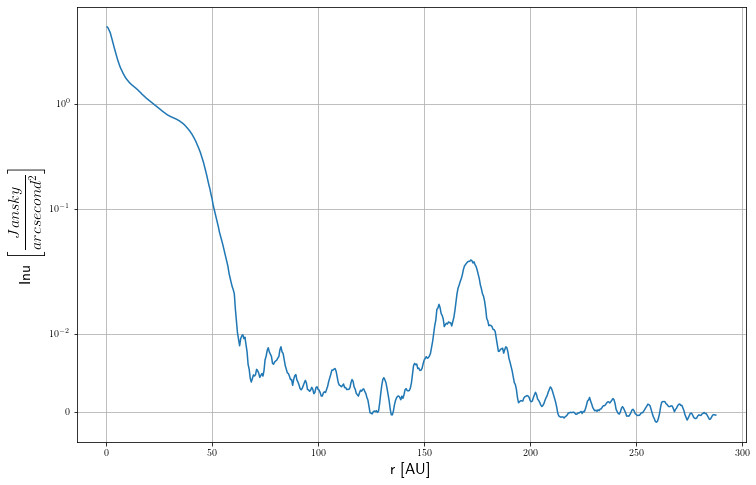

In [5]:
%matplotlib inline
plt.rcParams["figure.figsize"] = (12,8)
r_au, Inu = alma_disk(filename)

#### Displaying values

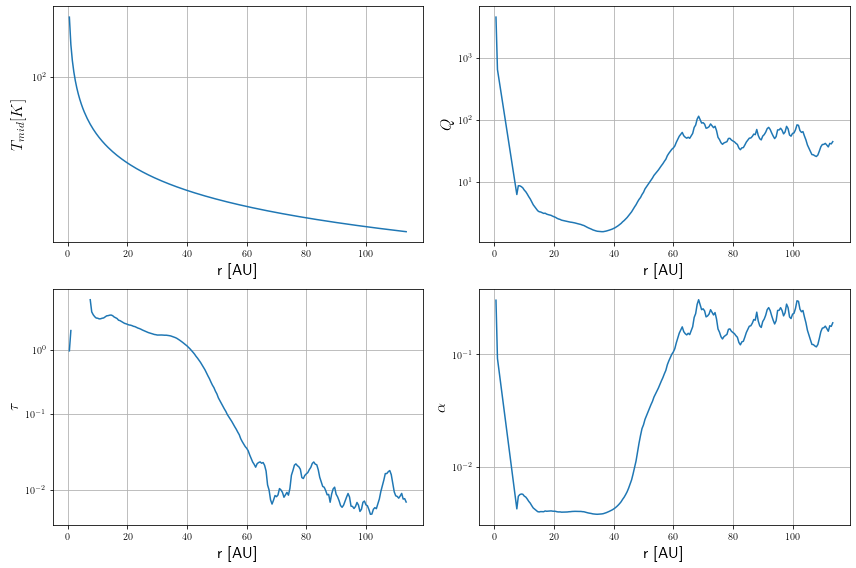

In [6]:
xlow = 0
xhigh = 114
plt.rcParams["figure.figsize"] = (12,8)
r_au_val, bol, T_mid, B_nu, tau_nu, sigma, cs, alpha, Omega_k, Q = alma_ana(xlow,xhigh,r_au,Inu,mstar,L_sol,nu,macc,mu,kappa_dust)

#### Difference in gas-dust speed

Now from this we can calculate the speed difference between the gas and the dust trying to go in kepler circles by

$$\Delta V=V_{g a s}-V_{d u s t}=\frac{1}{2}\left(\frac{V_{K}^{2}}{r}\right)^{-1}\left(\frac{1}{\rho} \frac{d P}{d r}\right) V_{K}$$


We use that $$\rho_{g}(z)=\rho_{0} \exp \left(-\frac{1}{2} \frac{z^{2}}{H_{\mathrm{p}}^{2}}\right)$$

with 

$$\rho_{0}=\frac{\Sigma_{\mathrm{g}}}{\sqrt{2 \pi} H_{\mathrm{p}}}$$

Where we assume $z=0$ and that $H_p = \frac{c_s}{\Omega_k}$

In [21]:
H = cs/Omega_k
vis = alpha * cs * H
sigma_g = sigma * 100

rho0 = (sigma_g/(H*np.sqrt(2*np.pi)))
dpdr = np.gradient(rho0*cs**2,0.5*u.au)   
# Based on P = rho * cs**2 and rho0 = rho
vk = np.sqrt(mstar*const.G/r_au_val)

dv = 1/2 * (vk**2/2)**(-1) * (1/rho0 * dpdr)*vk

Text(0, 0.5, ' $\\Delta V$ [$\\frac{m}{s}$]')

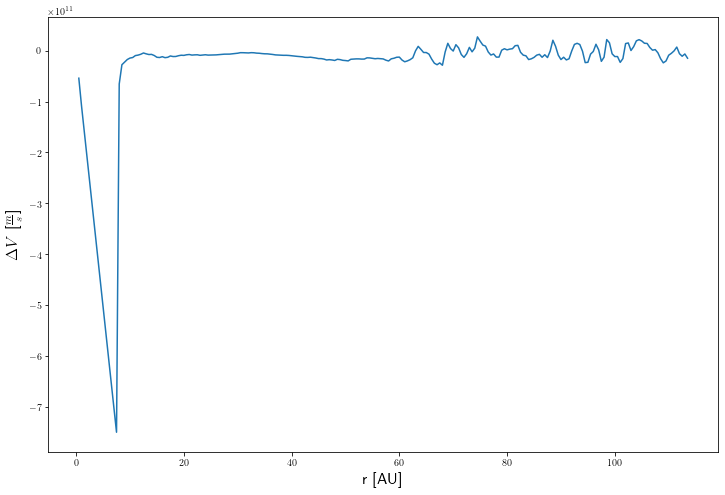

In [53]:
%matplotlib inline
plt.rcParams["figure.figsize"] = (12,8)
plt.plot(r_au_val,dv)
plt.yscale("linear")
plt.xlabel("r [AU]",fontsize="16")
plt.ylabel(r" $\Delta V$ [$\frac{m}{s}$]",fontsize="16")

#### Looking at drift speed

Next we calculate the settling speed which is dependent on

$$\mathrm{St}=\frac{\rho_{\mathrm{s}} \cdot a}{\Sigma_{\mathrm{g}}} \cdot \frac{\pi}{2} \quad \text { for } a<\frac{9}{4} \lambda_{\mathrm{mfp}}$$

where 

$$v_{d r i f t}=\frac{1}{S t+S t^{-1}} \frac{c_{S}^{2}}{V_{K}} \frac{d \ln P}{d \ln r}$$

since $P\propto r^{-2}$

In [23]:
s = 1*u.micron
cross = np.pi * s**2 #Cross-section af støvkorn
rhos = 1.6 * u.g / u.cm**3 # Densitet af støvkorn
# st =  Omega_k * (s * rhos)/(cs*)
st = (rhos * s /(sigma_g)  * np.pi/2 ).decompose()

vdrift = -2/(st + 1/st) * cs**2/vk 

Text(0, 0.5, ' $v_{drift}$ [$\\frac{m}{s}$]')

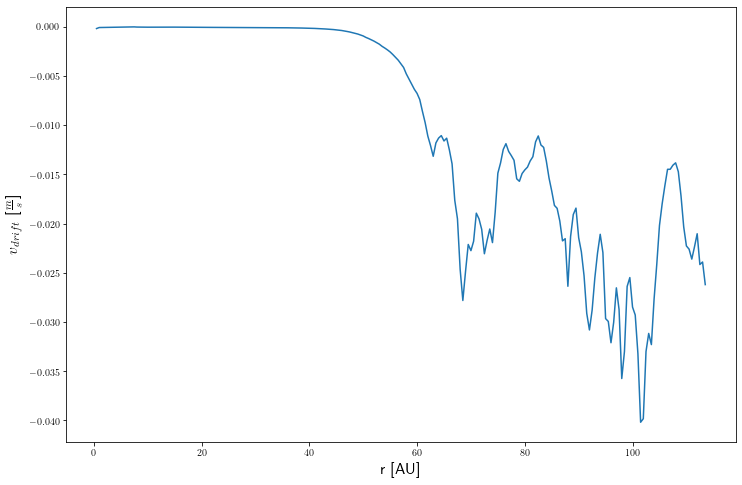

In [54]:
plt.plot(r_au_val,vdrift.decompose())
plt.xlabel("r [AU]",fontsize="16")
plt.ylabel(r" $v_{drift}$ [$\frac{m}{s}$]",fontsize="16")


#### Calculating settling speed at given r


$$u_{\text {sett }}=-z \Omega_{\mathrm{k}} \min \left(\mathrm{St}, \frac{1}{2}\right)$$

between 0 and r/10 AU

In [25]:
au = 10
ind = np.array(r_au_val) == au

##### Orbits to settle particle

In [ ]:
1/(2*np.pi*st[ind])

In [26]:
z = np.linspace(0,max(r_au_val)/10,100)* u.au
uset = - z * Omega_k[ind] * min(st[ind],1/2)

Text(0, 0.5, ' $u_{settling}$ [$\\frac{m}{s}$]')

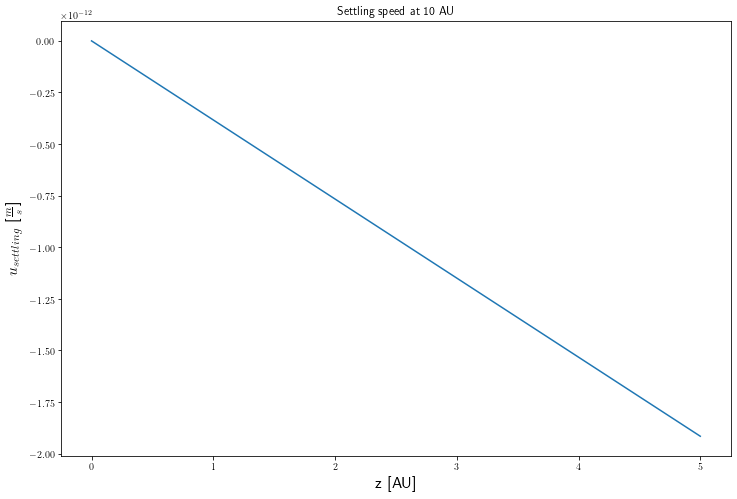

In [55]:
plt.plot(z,uset)
plt.title(f"Settling speed at {au} AU" )
plt.xlabel("z [AU]",fontsize="16")
plt.ylabel(r" $u_{settling}$ [$\frac{m}{s}$]",fontsize="16")